### modeling_4th_elo

Elo with season reversion alpha grid and home-field-advantage grid

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

df23 = pd.read_csv("model_df_2023.csv")
df24 = pd.read_csv("model_df_2024.csv")
df25 = pd.read_csv("model_df_2025.csv")

base_df = pd.concat([df23, df24, df25], axis=0, ignore_index=True)

print(base_df.shape)
print(base_df.head())
print(base_df.columns.tolist())

(2114, 70)
    game_id            game_date  season  home_team_code  away_team_code  \
0  20230711  2023-03-23 04:00:00    2023           10001            1001   
1  20230712  2023-03-23 04:00:00    2023           12001            5002   
2  20230716  2023-03-24 04:00:00    2023           10001            1001   
3  20230717  2023-03-24 04:00:00    2023           12001            5002   
4  20230718  2023-03-24 04:00:00    2023            7002            6002   

   stadium_code  home_sp_id  away_sp_id home_sp_name away_sp_name  ...  \
0          1003       14674       11404          김동혁          장필준  ...   
1          2002       11318       14780          엄상백          강효종  ...   
2          1003       11379       14613          최원태          허윤동  ...   
3          2002       15542       13102           슐서          김영준  ...   
4          4001       10610       13061          장민재           곽빈  ...   

   top5_OPS_diff  top5_OBP_diff  sp_ERA_diff  sp_FIP_diff sp_WHIP_diff  \
0       0.015

In [2]:
base_df = base_df.copy()
base_df["game_date"] = pd.to_datetime(base_df["game_date"], errors="coerce")

score_cols = ["home_score", "away_score", "home_win", "y_home_win"]
for col in score_cols:
    if col in base_df.columns:
        base_df[col] = pd.to_numeric(base_df[col], errors="coerce")

base_df["elo_result_home"] = np.where(
    base_df["home_score"] > base_df["away_score"], 1.0,
    np.where(base_df["home_score"] < base_df["away_score"], 0.0, 0.5)
)

base_df = base_df.sort_values(["game_date", "game_id"]).reset_index(drop=True)

draw_mask = (
    base_df["home_score"].notna()
    & base_df["away_score"].notna()
    & (base_df["home_score"] == base_df["away_score"])
)

print("draw games:", int(draw_mask.sum()))
display(base_df.loc[draw_mask, ["game_id", "game_date", "home_score", "away_score", "home_win", "elo_result_home"]].head(14))
display(base_df["elo_result_home"].value_counts(dropna=False).sort_index())

draw games: 43


,game_id,game_date,home_score,away_score,home_win,elo_result_home
9,20230723,2023-03-25 04:00:00,5.0,5.0,0,0.5
10,20230724,2023-03-25 09:00:00,4.0,4.0,0,0.5
77,20230059,2023-04-14 09:30:00,7.0,7.0,0,0.5
114,20230096,2023-04-23 05:00:00,1.0,1.0,0,0.5
191,20230188,2023-05-14 05:00:00,3.0,3.0,0,0.5
212,20230211,2023-05-20 08:00:00,1.0,1.0,0,0.5
283,20230287,2023-06-07 09:30:00,5.0,5.0,0,0.5
325,20230329,2023-06-16 09:30:00,2.0,2.0,0,0.5
336,20230340,2023-06-18 08:00:00,7.0,7.0,0,0.5
448,20230477,2023-07-28 09:30:00,5.0,5.0,0,0.5


elo_result_home
0.0    1013
0.5      43
1.0    1058
Name: count, dtype: int64

In [3]:
def make_team_game_log(game_df: pd.DataFrame) -> pd.DataFrame:
    base_cols = ["game_id", "game_date", "season"]

    home = game_df[base_cols + ["home_team_code", "away_team_code", "home_score", "away_score", "elo_result_home"]].copy()
    home = home.rename(columns={"home_team_code": "team_code", "away_team_code": "opponent_team_code", "home_score": "runs_for", "away_score": "runs_against", "elo_result_home": "result"})
    home["is_home"] = 1

    away = game_df[base_cols + ["away_team_code", "home_team_code", "away_score", "home_score", "elo_result_home"]].copy()
    away = away.rename(columns={"away_team_code": "team_code", "home_team_code": "opponent_team_code", "away_score": "runs_for", "home_score": "runs_against"})
    away["result"] = 1.0 - pd.to_numeric(away["elo_result_home"], errors="coerce")
    away = away.drop(columns=["elo_result_home"])
    away["is_home"] = 0

    team_games = pd.concat([home, away], ignore_index=True)
    team_games["game_date"] = pd.to_datetime(team_games["game_date"], errors="coerce")
    team_games["team_code"] = team_games["team_code"].astype(str)
    team_games["opponent_team_code"] = team_games["opponent_team_code"].astype(str)
    team_games["runs_for"] = pd.to_numeric(team_games["runs_for"], errors="coerce")
    team_games["runs_against"] = pd.to_numeric(team_games["runs_against"], errors="coerce")
    team_games["result"] = pd.to_numeric(team_games["result"], errors="coerce")
    team_games["run_diff"] = team_games["runs_for"] - team_games["runs_against"]

    return team_games.sort_values(["team_code", "game_date", "game_id"]).reset_index(drop=True)


def build_recent_team_features(game_df: pd.DataFrame, windows=(5, 10)):
    team_recent = make_team_game_log(game_df)
    team_recent = team_recent.sort_values(["team_code", "game_date", "game_id"]).reset_index(drop=True)
    grouped = team_recent.groupby(["team_code", "season"], group_keys=False)

    team_recent["prev_game_date"] = grouped["game_date"].shift(1)
    team_recent["rest_days"] = (team_recent["game_date"].dt.normalize() - team_recent["prev_game_date"].dt.normalize()).dt.days - 1
    team_recent["rest_days"] = team_recent["rest_days"].clip(lower=0)
    team_recent["prev_game_result"] = grouped["result"].shift(1)

    rolling_targets = {"result": "result_avg", "runs_for": "runs_for_avg", "runs_against": "runs_against_avg", "run_diff": "run_diff_avg"}

    for window in windows:
        for src_col, out_name in rolling_targets.items():
            out_col = f"recent_{window}_{out_name}"
            team_recent[out_col] = grouped[src_col].transform(lambda s, w=window: s.shift(1).rolling(w, min_periods=1).mean())

    feature_cols = ["game_id", "team_code", "rest_days", "prev_game_result"]
    feature_cols += [c for c in team_recent.columns if c.startswith("recent_")]
    recent_features = team_recent[feature_cols].copy()

    home_recent = recent_features.rename(columns={c: f"home_{c}" for c in feature_cols if c not in ["game_id", "team_code"]}).rename(columns={"team_code": "home_team_code"})
    away_recent = recent_features.rename(columns={c: f"away_{c}" for c in feature_cols if c not in ["game_id", "team_code"]}).rename(columns={"team_code": "away_team_code"})

    out = game_df.copy()
    out["home_team_code"] = out["home_team_code"].astype(str)
    out["away_team_code"] = out["away_team_code"].astype(str)
    out = out.merge(home_recent, on=["game_id", "home_team_code"], how="left")
    out = out.merge(away_recent, on=["game_id", "away_team_code"], how="left")

    diff_pairs = ["rest_days", "prev_game_result"] + [c for c in team_recent.columns if c.startswith("recent_")]
    for col in diff_pairs:
        out[f"{col}_diff"] = out[f"home_{col}"] - out[f"away_{col}"]

    return out, team_recent


model_base_df, team_recent = build_recent_team_features(base_df, windows=(5, 10))
recent_diff_cols = [c for c in model_base_df.columns if c.startswith("recent_") and c.endswith("_diff")]
recent_diff_cols += ["rest_days_diff", "prev_game_result_diff"]

print(model_base_df.shape)
print(recent_diff_cols)
display(model_base_df[["game_id", "game_date", "home_team_code", "away_team_code"] + recent_diff_cols].head(12))

(2114, 101)
['recent_5_result_avg_diff', 'recent_5_runs_for_avg_diff', 'recent_5_runs_against_avg_diff', 'recent_5_run_diff_avg_diff', 'recent_10_result_avg_diff', 'recent_10_runs_for_avg_diff', 'recent_10_runs_against_avg_diff', 'recent_10_run_diff_avg_diff', 'rest_days_diff', 'prev_game_result_diff']


,game_id,game_date,home_team_code,away_team_code,recent_5_result_avg_diff,recent_5_runs_for_avg_diff,recent_5_runs_against_avg_diff,recent_5_run_diff_avg_diff,recent_10_result_avg_diff,recent_10_runs_for_avg_diff,recent_10_runs_against_avg_diff,recent_10_run_diff_avg_diff,rest_days_diff,prev_game_result_diff
0,20230711,2023-03-23 04:00:00,10001,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,20230712,2023-03-23 04:00:00,12001,5002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,20230716,2023-03-24 04:00:00,10001,1001,-1.0,-1.0,1.0,-2.0,-1.0,-1.0,1.0,-2.0,0.0,-1.0
3,20230717,2023-03-24 04:00:00,12001,5002,-1.0,-4.0,4.0,-8.0,-1.0,-4.0,4.0,-8.0,0.0,-1.0
4,20230718,2023-03-24 04:00:00,7002,6002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,20230719,2023-03-24 04:00:00,2002,9002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,20230720,2023-03-24 04:00:00,11001,3001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,20230721,2023-03-25 04:00:00,6002,1001,0.0,5.0,-1.0,6.0,0.0,5.0,-1.0,6.0,0.0,0.0
8,20230722,2023-03-25 04:00:00,10001,5002,-0.5,0.5,0.5,0.0,-0.5,0.5,0.5,0.0,0.0,0.0
9,20230723,2023-03-25 04:00:00,12001,9002,-0.5,1.5,1.5,0.0,-0.5,1.5,1.5,0.0,0.0,0.0


In [4]:
ALPHA_LIST = [0.5, 0.65, 0.8]
HOME_FIELD_ADV_LIST = [20, 25, 30]
BASE_ELO = 1500.0
K_FACTOR = 20.0


def expected_home_score(home_elo: float, away_elo: float, home_field_adv: float = 0.0) -> float:
    return 1.0 / (1.0 + 10 ** (((away_elo) - (home_elo + home_field_adv)) / 400.0))


def regress_to_mean(old_elo: float, alpha: float, base_elo: float = 1500.0) -> float:
    return base_elo + alpha * (old_elo - base_elo)


def build_elo_features(game_df: pd.DataFrame, alpha: float, home_field_adv: float, base_elo: float = 1500.0, k_factor: float = 20.0) -> pd.DataFrame:
    elo_df = game_df.copy().sort_values(["game_date", "game_id"]).reset_index(drop=True)
    elo_df["home_team_code"] = elo_df["home_team_code"].astype(str)
    elo_df["away_team_code"] = elo_df["away_team_code"].astype(str)

    ratings = {}
    last_seen_season = {}
    home_elo_pre_list = []
    away_elo_pre_list = []
    elo_exp_home_list = []
    home_elo_post_list = []
    away_elo_post_list = []

    for row in elo_df.itertuples(index=False):
        season = row.season
        home_team = row.home_team_code
        away_team = row.away_team_code

        for team in [home_team, away_team]:
            if team not in ratings:
                ratings[team] = base_elo
                last_seen_season[team] = season
            elif last_seen_season[team] != season:
                ratings[team] = regress_to_mean(ratings[team], alpha=alpha, base_elo=base_elo)
                last_seen_season[team] = season

        result_home = row.elo_result_home
        home_elo_pre = ratings[home_team]
        away_elo_pre = ratings[away_team]
        elo_exp_home = expected_home_score(home_elo_pre, away_elo_pre, home_field_adv=home_field_adv)

        elo_delta = k_factor * (result_home - elo_exp_home)
        home_elo_post = home_elo_pre + elo_delta
        away_elo_post = away_elo_pre - elo_delta

        ratings[home_team] = home_elo_post
        ratings[away_team] = away_elo_post
        last_seen_season[home_team] = season
        last_seen_season[away_team] = season

        home_elo_pre_list.append(home_elo_pre)
        away_elo_pre_list.append(away_elo_pre)
        elo_exp_home_list.append(elo_exp_home)
        home_elo_post_list.append(home_elo_post)
        away_elo_post_list.append(away_elo_post)

    elo_df["home_elo_pre"] = home_elo_pre_list
    elo_df["away_elo_pre"] = away_elo_pre_list
    elo_df["elo_diff"] = elo_df["home_elo_pre"] - elo_df["away_elo_pre"]
    elo_df["elo_exp_home"] = elo_exp_home_list
    elo_df["home_elo_post"] = home_elo_post_list
    elo_df["away_elo_post"] = away_elo_post_list
    elo_df["elo_alpha"] = alpha
    elo_df["home_field_adv"] = home_field_adv

    return elo_df

In [5]:
elo_feature_candidates = ["home_elo_pre", "away_elo_pre", "elo_diff", "elo_exp_home"]
sp_feature_candidates = ["sp_ERA_diff", "sp_FIP_diff", "sp_WHIP_diff", "sp_K9_diff", "sp_BB9_diff", "sp_HR9_diff", "sp_KBB_diff"]
lineup_feature_candidates = ["lineup_OPS_diff", "lineup_OBP_diff", "lineup_SLG_diff", "top5_OPS_diff", "top5_OBP_diff"]
recent_feature_candidates = ["recent_5_result_avg_diff", "recent_5_runs_for_avg_diff", "recent_5_runs_against_avg_diff", "recent_5_run_diff_avg_diff", "recent_10_result_avg_diff", "recent_10_runs_for_avg_diff", "recent_10_runs_against_avg_diff", "recent_10_run_diff_avg_diff", "rest_days_diff", "prev_game_result_diff"]

sp_feature_cols = [c for c in sp_feature_candidates if c in model_base_df.columns]
lineup_feature_cols = [c for c in lineup_feature_candidates if c in model_base_df.columns]
recent_feature_cols = [c for c in recent_feature_candidates if c in model_base_df.columns]

print("sp_feature_cols:", sp_feature_cols)
print("lineup_feature_cols:", lineup_feature_cols)
print("recent_feature_cols:", recent_feature_cols)

sp_feature_cols: ['sp_ERA_diff', 'sp_FIP_diff', 'sp_WHIP_diff', 'sp_K9_diff', 'sp_BB9_diff', 'sp_HR9_diff', 'sp_KBB_diff']
lineup_feature_cols: ['lineup_OPS_diff', 'lineup_OBP_diff', 'lineup_SLG_diff', 'top5_OPS_diff', 'top5_OBP_diff']
recent_feature_cols: ['recent_5_result_avg_diff', 'recent_5_runs_for_avg_diff', 'recent_5_runs_against_avg_diff', 'recent_5_run_diff_avg_diff', 'recent_10_result_avg_diff', 'recent_10_runs_for_avg_diff', 'recent_10_runs_against_avg_diff', 'recent_10_run_diff_avg_diff', 'rest_days_diff', 'prev_game_result_diff']


In [6]:
def make_logit_model(C=1.0):
    return Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000, random_state=427, C=C))])


def evaluate_model_block(model_name, model, feature_cols, fit_df, eval_df):
    required_cols = feature_cols + ["y_home_win"]
    fit_ready = fit_df.dropna(subset=required_cols).copy()
    eval_ready = eval_df.dropna(subset=required_cols).copy()

    X_fit = fit_ready[feature_cols].copy()
    y_fit = fit_ready["y_home_win"].astype(int).copy()
    X_eval = eval_ready[feature_cols].copy()
    y_eval = eval_ready["y_home_win"].astype(int).copy()

    model.fit(X_fit, y_fit)
    y_fit_pred = model.predict(X_fit)
    y_fit_proba = model.predict_proba(X_fit)[:, 1]
    y_eval_pred = model.predict(X_eval)
    y_eval_proba = model.predict_proba(X_eval)[:, 1]

    result = {
        "model": model_name,
        "n_features": len(feature_cols),
        "fit_n": len(fit_ready),
        "eval_n": len(eval_ready),
        "fit_acc": accuracy_score(y_fit, y_fit_pred),
        "eval_acc": accuracy_score(y_eval, y_eval_pred),
        "fit_auc": roc_auc_score(y_fit, y_fit_proba),
        "eval_auc": roc_auc_score(y_eval, y_eval_proba),
        "fit_brier": brier_score_loss(y_fit, y_fit_proba),
        "eval_brier": brier_score_loss(y_eval, y_eval_proba),
    }

    pred_df = eval_ready[["game_id", "game_date", "season", "home_team_code", "away_team_code", "home_score", "away_score"]].copy()
    pred_df["y_true"] = y_eval.values
    pred_df["y_pred"] = y_eval_pred
    pred_df["y_proba"] = y_eval_proba
    pred_df["correct"] = (pred_df["y_true"] == pred_df["y_pred"]).astype(int)

    return result, pred_df

In [7]:
results = []
roc_plot_rows = []

for alpha in ALPHA_LIST:
    for home_field_adv in HOME_FIELD_ADV_LIST:
        combo_df = build_elo_features(model_base_df, alpha=alpha, home_field_adv=home_field_adv, base_elo=BASE_ELO, k_factor=K_FACTOR)

        elo_feature_cols = [c for c in elo_feature_candidates if c in combo_df.columns]
        feature_cols_elo_sp = sp_feature_cols + recent_feature_cols + elo_feature_cols
        feature_cols_elo_full = lineup_feature_cols + sp_feature_cols + recent_feature_cols + elo_feature_cols

        model_input = combo_df.copy()
        model_input[recent_feature_cols] = model_input[recent_feature_cols].fillna(0)

        train_2023_df = model_input[model_input["season"] == 2023].copy()
        test_2024_df = model_input[model_input["season"] == 2024].copy()
        train_2324_df = model_input[model_input["season"] <= 2024].copy()
        test_2025_df = model_input[model_input["season"] == 2025].copy()

        for model_type, feature_cols in {"elo_sp": feature_cols_elo_sp, "elo_full": feature_cols_elo_full}.items():
            model_23_to_24 = make_logit_model(C=1.0)
            result_23_to_24, pred_2024 = evaluate_model_block(f"{model_type}_a{alpha}_h{home_field_adv}_2023_train_2024_test", model_23_to_24, feature_cols, train_2023_df, test_2024_df)
            result_23_to_24["alpha"] = alpha
            result_23_to_24["home_field_adv"] = home_field_adv
            result_23_to_24["model_type"] = model_type
            result_23_to_24["eval_split"] = "2023_train_2024_test"
            results.append(result_23_to_24)

            model_2324_to_25 = make_logit_model(C=1.0)
            result_2324_to_25, pred_2025 = evaluate_model_block(f"{model_type}_a{alpha}_h{home_field_adv}_2023_2024_train_2025_test", model_2324_to_25, feature_cols, train_2324_df, test_2025_df)
            result_2324_to_25["alpha"] = alpha
            result_2324_to_25["home_field_adv"] = home_field_adv
            result_2324_to_25["model_type"] = model_type
            result_2324_to_25["eval_split"] = "2023_2024_train_2025_test"
            results.append(result_2324_to_25)

            roc_plot_rows.append({"alpha": alpha, "home_field_adv": home_field_adv, "model_type": model_type, "y_true": pred_2025["y_true"].astype(int).values, "y_proba": pred_2025["y_proba"].astype(float).values, "auc": result_2324_to_25["eval_auc"]})

results_df = pd.DataFrame(results)
roc_plot_df = pd.DataFrame(roc_plot_rows)
display(results_df.round(4))

,model,n_features,fit_n,eval_n,fit_acc,eval_acc,fit_auc,eval_auc,fit_brier,eval_brier,alpha,home_field_adv,model_type,eval_split
0,elo_sp_a0.5_h20_2023_train_2024_test,21,658,711,0.6231,0.5893,0.6676,0.6204,0.2289,0.2413,0.50,20,elo_sp,2023_train_2024_test
1,elo_sp_a0.5_h20_2023_2024_train_2025_test,21,1369,709,0.6092,0.5952,0.6498,0.6417,0.2324,0.2356,0.50,20,elo_sp,2023_2024_train_2025_test
2,elo_full_a0.5_h20_2023_train_2024_test,26,658,711,0.6322,0.5837,0.6882,0.6335,0.2236,0.2396,0.50,20,elo_full,2023_train_2024_test
3,elo_full_a0.5_h20_2023_2024_train_2025_test,26,1369,709,0.6114,0.6051,0.6648,0.6396,0.2290,0.2362,0.50,20,elo_full,2023_2024_train_2025_test
4,elo_sp_a0.5_h25_2023_train_2024_test,21,658,711,0.6231,0.5879,0.6676,0.6203,0.2289,0.2413,0.50,25,elo_sp,2023_train_2024_test
5,elo_sp_a0.5_h25_2023_2024_train_2025_test,21,1369,709,0.6085,0.5952,0.6497,0.6415,0.2324,0.2356,0.50,25,elo_sp,2023_2024_train_2025_test
6,elo_full_a0.5_h25_2023_train_2024_test,26,658,711,0.6353,0.5837,0.6881,0.6335,0.2236,0.2396,0.50,25,elo_full,2023_train_2024_test
7,elo_full_a0.5_h25_2023_2024_train_2025_test,26,1369,709,0.6121,0.6065,0.6648,0.6396,0.2290,0.2362,0.50,25,elo_full,2023_2024_train_2025_test
8,elo_sp_a0.5_h30_2023_train_2024_test,21,658,711,0.6231,0.5879,0.6678,0.6201,0.2289,0.2413,0.50,30,elo_sp,2023_train_2024_test
9,elo_sp_a0.5_h30_2023_2024_train_2025_test,21,1369,709,0.6092,0.5938,0.6497,0.6416,0.2324,0.2355,0.50,30,elo_sp,2023_2024_train_2025_test


In [8]:
results_2025 = results_df[results_df["eval_split"] == "2023_2024_train_2025_test"].copy()

sp_acc_pivot = results_2025[results_2025["model_type"] == "elo_sp"].pivot(index="alpha", columns="home_field_adv", values="eval_acc")
sp_auc_pivot = results_2025[results_2025["model_type"] == "elo_sp"].pivot(index="alpha", columns="home_field_adv", values="eval_auc")
full_acc_pivot = results_2025[results_2025["model_type"] == "elo_full"].pivot(index="alpha", columns="home_field_adv", values="eval_acc")
full_auc_pivot = results_2025[results_2025["model_type"] == "elo_full"].pivot(index="alpha", columns="home_field_adv", values="eval_auc")

print("=== SP accuracy (2025) ===")
display(sp_acc_pivot.round(4))
print("=== SP AUC (2025) ===")
display(sp_auc_pivot.round(4))
print("=== FULL accuracy (2025) ===")
display(full_acc_pivot.round(4))
print("=== FULL AUC (2025) ===")
display(full_auc_pivot.round(4))
print("=== Best combinations by eval_auc (2025) ===")
display(results_2025.sort_values(["model_type", "eval_auc"], ascending=[True, False]).round(4))

=== SP accuracy (2025) ===


home_field_adv,20,25,30
alpha,,,
0.50,0.5952,0.5952,0.5938
0.65,0.6008,0.6008,0.5994
0.80,0.5994,0.5994,0.5994


=== SP AUC (2025) ===


home_field_adv,20,25,30
alpha,,,
0.50,0.6417,0.6415,0.6416
0.65,0.6413,0.6411,0.6413
0.80,0.6409,0.6410,0.6409


=== FULL accuracy (2025) ===


home_field_adv,20,25,30
alpha,,,
0.50,0.6051,0.6065,0.6037
0.65,0.6023,0.6037,0.6023
0.80,0.6008,0.6023,0.6023


=== FULL AUC (2025) ===


home_field_adv,20,25,30
alpha,,,
0.50,0.6396,0.6396,0.6397
0.65,0.6399,0.6398,0.6399
0.80,0.6398,0.6398,0.6398


=== Best combinations by eval_auc (2025) ===


,model,n_features,fit_n,eval_n,fit_acc,eval_acc,fit_auc,eval_auc,fit_brier,eval_brier,alpha,home_field_adv,model_type,eval_split
15,elo_full_a0.65_h20_2023_2024_train_2025_test,26,1369,709,0.6114,0.6023,0.6647,0.6399,0.2290,0.2361,0.65,20,elo_full,2023_2024_train_2025_test
23,elo_full_a0.65_h30_2023_2024_train_2025_test,26,1369,709,0.6107,0.6023,0.6647,0.6399,0.2290,0.2361,0.65,30,elo_full,2023_2024_train_2025_test
19,elo_full_a0.65_h25_2023_2024_train_2025_test,26,1369,709,0.6114,0.6037,0.6647,0.6398,0.2290,0.2361,0.65,25,elo_full,2023_2024_train_2025_test
31,elo_full_a0.8_h25_2023_2024_train_2025_test,26,1369,709,0.6121,0.6023,0.6645,0.6398,0.2290,0.2362,0.80,25,elo_full,2023_2024_train_2025_test
35,elo_full_a0.8_h30_2023_2024_train_2025_test,26,1369,709,0.6121,0.6023,0.6645,0.6398,0.2290,0.2362,0.80,30,elo_full,2023_2024_train_2025_test
27,elo_full_a0.8_h20_2023_2024_train_2025_test,26,1369,709,0.6129,0.6008,0.6645,0.6398,0.2290,0.2362,0.80,20,elo_full,2023_2024_train_2025_test
11,elo_full_a0.5_h30_2023_2024_train_2025_test,26,1369,709,0.6121,0.6037,0.6648,0.6397,0.2290,0.2362,0.50,30,elo_full,2023_2024_train_2025_test
7,elo_full_a0.5_h25_2023_2024_train_2025_test,26,1369,709,0.6121,0.6065,0.6648,0.6396,0.2290,0.2362,0.50,25,elo_full,2023_2024_train_2025_test
3,elo_full_a0.5_h20_2023_2024_train_2025_test,26,1369,709,0.6114,0.6051,0.6648,0.6396,0.2290,0.2362,0.50,20,elo_full,2023_2024_train_2025_test
1,elo_sp_a0.5_h20_2023_2024_train_2025_test,21,1369,709,0.6092,0.5952,0.6498,0.6417,0.2324,0.2356,0.50,20,elo_sp,2023_2024_train_2025_test


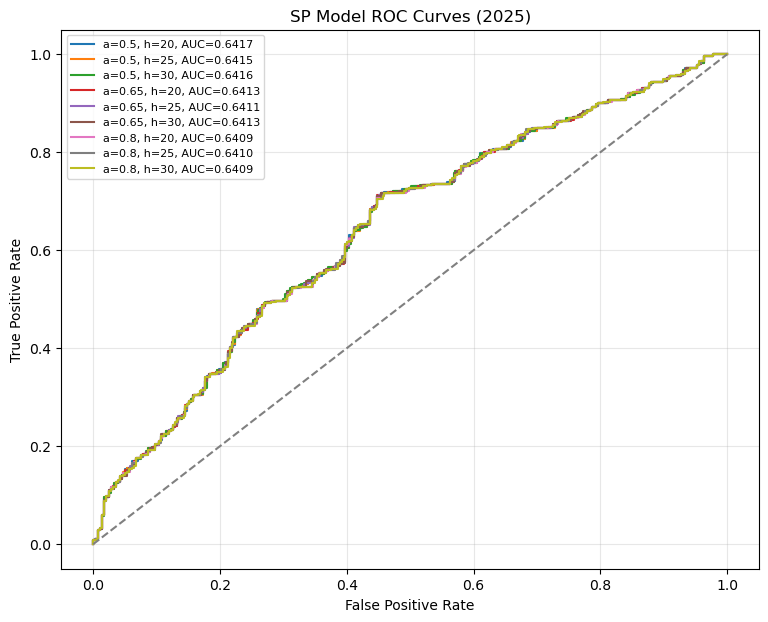

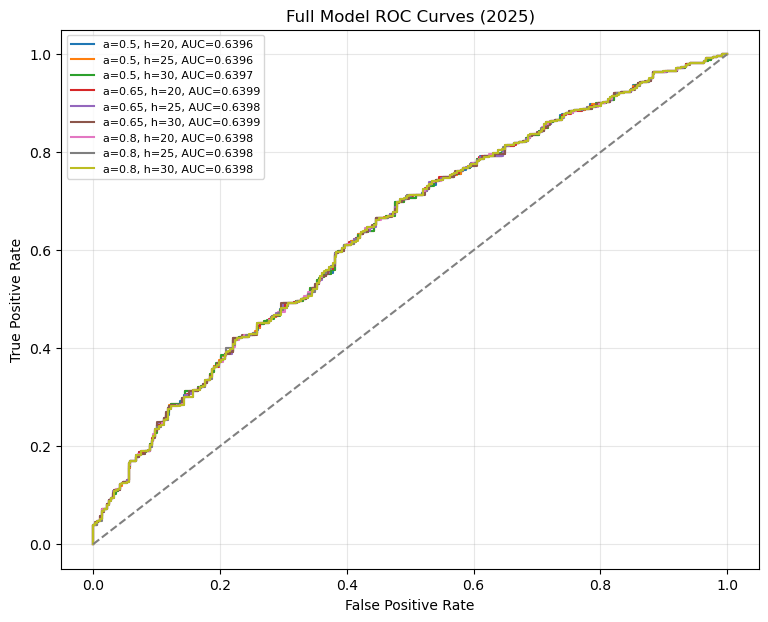

In [9]:
for model_type, title in [("elo_sp", "SP Model ROC Curves (2025)"), ("elo_full", "Full Model ROC Curves (2025)")]:
    plt.figure(figsize=(9, 7))
    plot_rows = roc_plot_df[roc_plot_df["model_type"] == model_type].copy()
    for row in plot_rows.itertuples(index=False):
        fpr, tpr, _ = roc_curve(row.y_true, row.y_proba)
        plt.plot(fpr, tpr, label=f"a={row.alpha}, h={row.home_field_adv}, AUC={row.auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.title(title)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.show()

### Final Fixed Hyperparameters

Train and save final models with `ALPHA = 0.65` and `HOME_FIELD_ADV = 25`.

In [28]:
import joblib

FINAL_ALPHA = 0.65
FINAL_HOME_FIELD_ADV = 25

final_df = build_elo_features(model_base_df, alpha=FINAL_ALPHA, home_field_adv=FINAL_HOME_FIELD_ADV, base_elo=BASE_ELO, k_factor=K_FACTOR)
final_elo_feature_cols = [c for c in elo_feature_candidates if c in final_df.columns]

# Keep the saved core feature sets and add only elo-related features.
feature_cols_recent_core = joblib.load("feature_cols_reduced_core.pkl")
feature_cols_recent_core_sp = joblib.load("feature_cols_recent_reduce_core_sp.pkl")

feature_cols_recent_core = [c for c in feature_cols_recent_core if c in final_df.columns]
feature_cols_recent_core_sp = [c for c in feature_cols_recent_core_sp if c in final_df.columns]

feature_cols_elo_full = feature_cols_recent_core + [c for c in final_elo_feature_cols if c not in feature_cols_recent_core]
feature_cols_elo_sp = feature_cols_recent_core_sp + [c for c in final_elo_feature_cols if c not in feature_cols_recent_core_sp]

final_model_input = final_df.copy()
final_model_input[recent_feature_cols] = final_model_input[recent_feature_cols].fillna(0)

display(final_df[["game_id", "game_date", "home_elo_pre", "away_elo_pre", "elo_diff", "elo_exp_home"]].head(10))
print("feature_cols_recent_core:", len(feature_cols_recent_core))
print(feature_cols_recent_core)
print("feature_cols_recent_core_sp:", len(feature_cols_recent_core_sp))
print(feature_cols_recent_core_sp)
print("feature_cols_elo_sp:", len(feature_cols_elo_sp))
print(feature_cols_elo_sp)
print("feature_cols_elo_full:", len(feature_cols_elo_full))
print(feature_cols_elo_full)

,game_id,game_date,home_elo_pre,away_elo_pre,elo_diff,elo_exp_home
0,20230711,2023-03-23 04:00:00,1500.000000,1500.000000,0.000000,0.535916
1,20230712,2023-03-23 04:00:00,1500.000000,1500.000000,0.000000,0.535916
2,20230716,2023-03-24 04:00:00,1489.281681,1510.718319,-21.436637,0.505128
3,20230717,2023-03-24 04:00:00,1489.281681,1510.718319,-21.436637,0.505128
4,20230718,2023-03-24 04:00:00,1500.000000,1500.000000,0.000000,0.535916
5,20230719,2023-03-24 04:00:00,1500.000000,1500.000000,0.000000,0.535916
6,20230720,2023-03-24 04:00:00,1500.000000,1500.000000,0.000000,0.535916
7,20230721,2023-03-25 04:00:00,1510.718319,1520.820877,-10.102558,0.521426
8,20230722,2023-03-25 04:00:00,1479.179123,1500.820877,-21.641754,0.504833
9,20230723,2023-03-25 04:00:00,1499.179123,1510.718319,-11.539195,0.519362


feature_cols_recent_core: 11
['lineup_OPS_diff', 'lineup_OBP_diff', 'sp_FIP_diff', 'sp_ERA_diff', 'sp_K9_diff', 'sp_BB9_diff', 'sp_HR9_diff', 'sp_KBB_diff', 'recent_5_run_diff_avg_diff', 'recent_5_runs_against_avg_diff', 'rest_days_diff']
feature_cols_recent_core_sp: 9
['sp_FIP_diff', 'sp_ERA_diff', 'sp_K9_diff', 'sp_BB9_diff', 'sp_HR9_diff', 'sp_KBB_diff', 'recent_5_run_diff_avg_diff', 'recent_5_runs_against_avg_diff', 'rest_days_diff']
feature_cols_elo_sp: 13
['sp_FIP_diff', 'sp_ERA_diff', 'sp_K9_diff', 'sp_BB9_diff', 'sp_HR9_diff', 'sp_KBB_diff', 'recent_5_run_diff_avg_diff', 'recent_5_runs_against_avg_diff', 'rest_days_diff', 'home_elo_pre', 'away_elo_pre', 'elo_diff', 'elo_exp_home']
feature_cols_elo_full: 15
['lineup_OPS_diff', 'lineup_OBP_diff', 'sp_FIP_diff', 'sp_ERA_diff', 'sp_K9_diff', 'sp_BB9_diff', 'sp_HR9_diff', 'sp_KBB_diff', 'recent_5_run_diff_avg_diff', 'recent_5_runs_against_avg_diff', 'rest_days_diff', 'home_elo_pre', 'away_elo_pre', 'elo_diff', 'elo_exp_home']


In [29]:
train_2023_df = final_model_input[final_model_input["season"] == 2023].copy()
test_2024_df = final_model_input[final_model_input["season"] == 2024].copy()
train_2324_df = final_model_input[final_model_input["season"] <= 2024].copy()
test_2025_df = final_model_input[final_model_input["season"] == 2025].copy()

logit_model_elo_sp_23_to_24 = make_logit_model(C=1.0)
result_elo_sp_23_to_24, pred_elo_sp_2024 = evaluate_model_block("elo_sp_alpha065_home25_2023_train_2024_test", logit_model_elo_sp_23_to_24, feature_cols_elo_sp, train_2023_df, test_2024_df)

logit_model_elo_sp = make_logit_model(C=1.0)
result_elo_sp_2324_to_25, pred_elo_sp_2025 = evaluate_model_block("elo_sp_alpha065_home25_2023_2024_train_2025_test", logit_model_elo_sp, feature_cols_elo_sp, train_2324_df, test_2025_df)

elo_sp_result = pd.DataFrame([result_elo_sp_23_to_24, result_elo_sp_2324_to_25])
display(elo_sp_result.round(4))
display(pred_elo_sp_2025.head(20))

joblib.dump(logit_model_elo_sp, "logit_model_elo_sp.pkl")
joblib.dump(feature_cols_elo_sp, "feature_cols_elo_sp.pkl")
print("saved: logit_model_elo_sp.pkl, feature_cols_elo_sp.pkl")

,model,n_features,fit_n,eval_n,fit_acc,eval_acc,fit_auc,eval_auc,fit_brier,eval_brier
0,elo_sp_alpha065_home25_2023_train_2024_test,13,658,711,0.6231,0.5907,0.6616,0.6210,0.2298,0.2414
1,elo_sp_alpha065_home25_2023_2024_train_2025_test,13,1369,709,0.6070,0.6234,0.6461,0.6545,0.2334,0.2328


,game_id,game_date,season,home_team_code,away_team_code,home_score,away_score,y_true,y_pred,y_proba,correct
1405,20250001,2025-03-22 05:00:00,2025,5002,3001,12.0,2.0,1,1,0.582661,1
1406,20250002,2025-03-22 05:00:00,2025,9002,6002,6.0,5.0,1,1,0.679655,1
1407,20250003,2025-03-22 05:00:00,2025,1001,10001,13.0,5.0,1,1,0.505273,1
1408,20250004,2025-03-22 05:00:00,2025,12001,7002,3.0,4.0,0,0,0.351392,1
1409,20250005,2025-03-22 05:00:00,2025,2002,11001,9.0,2.0,1,1,0.636560,1
1410,20250006,2025-03-23 05:00:00,2025,5002,3001,10.0,2.0,1,1,0.657440,1
1411,20250007,2025-03-23 05:00:00,2025,9002,6002,5.0,2.0,1,0,0.445593,0
1412,20250008,2025-03-23 05:00:00,2025,1001,10001,11.0,7.0,1,1,0.735955,1
1413,20250009,2025-03-23 05:00:00,2025,12001,7002,5.0,4.0,1,0,0.297392,0
1414,20250010,2025-03-23 05:00:00,2025,2002,11001,4.0,5.0,0,0,0.472863,1


saved: logit_model_elo_sp.pkl, feature_cols_elo_sp.pkl


In [32]:
home_elo_snapshot = final_df[["game_date", "game_id", "season", "home_team_code", "home_elo_post"]].copy()
home_elo_snapshot = home_elo_snapshot.rename(columns={"home_team_code": "team_code", "home_elo_post": "elo"})

away_elo_snapshot = final_df[["game_date", "game_id", "season", "away_team_code", "away_elo_post"]].copy()
away_elo_snapshot = away_elo_snapshot.rename(columns={"away_team_code": "team_code", "away_elo_post": "elo"})

team_elo_history = pd.concat([home_elo_snapshot, away_elo_snapshot], ignore_index=True)
team_elo_history = team_elo_history.sort_values(["team_code", "game_date", "game_id"]).reset_index(drop=True)

team_elo_snapshot = team_elo_history.groupby("team_code", as_index=False).tail(1).copy()
team_elo_snapshot = team_elo_snapshot.sort_values("team_code").reset_index(drop=True)
team_elo_snapshot_min = team_elo_snapshot[["team_code", "elo"]].copy()

team_elo_snapshot_min.to_csv("team_elo_snapshot.csv", index=False, encoding="utf-8-sig")

display(team_elo_snapshot_min)
print("saved: team_elo_snapshot.csv")

,team_code,elo
0,10001,1426.912834
1,1001,1552.109145
2,11001,1538.655689
3,12001,1523.694813
4,2002,1416.032372
5,3001,1411.500134
6,5002,1546.404834
7,6002,1464.943489
8,7002,1554.091957
9,9002,1565.654734


saved: team_elo_snapshot.csv


### Update Elo With 2026 Results

Load 2026 completed games from the API, regress 2025 Elo by alpha, and update to the latest 2026 Elo snapshot.

In [36]:
import importlib
import utils as ut
importlib.reload(ut)

from datetime import timedelta

UPDATE_TARGET_DATE = pd.Timestamp("2026-05-13")
UPDATE_SEASON_START = pd.Timestamp("2026-03-22")
UPDATE_FETCH_END = UPDATE_TARGET_DATE - timedelta(days=1)

update_date_list = pd.date_range(UPDATE_SEASON_START, UPDATE_FETCH_END, freq="D").strftime("%Y-%m-%d").tolist()
games_2026_raw = ut.collect_games(update_date_list, sleep_sec=0.2)
games_2026 = ut.prepare_games_for_modeling(games_2026_raw)
games_2026 = games_2026.copy()
games_2026["game_date"] = pd.to_datetime(games_2026["game_date"], errors="coerce")
games_2026["home_team_code"] = games_2026["home_team_code"].astype(str)
games_2026["away_team_code"] = games_2026["away_team_code"].astype(str)
games_2026 = games_2026.sort_values(["game_date", "game_id"]).reset_index(drop=True)
games_2026["elo_result_home"] = np.where(
    games_2026["home_score"] > games_2026["away_score"], 1.0,
    np.where(games_2026["home_score"] < games_2026["away_score"], 0.0, 0.5)
)

print(games_2026.shape)
display(games_2026[["game_id", "game_date", "season", "home_team_code", "away_team_code", "home_score", "away_score", "elo_result_home"]].tail())

[games] 2026-03-22: 5 rows
[games] 2026-03-23: 5 rows
[games] 2026-03-24: 5 rows
[games] 2026-03-25: 0 rows
[games] 2026-03-26: 0 rows
[games] 2026-03-27: 0 rows
[games] 2026-03-28: 5 rows
[games] 2026-03-29: 5 rows
[games] 2026-03-30: 0 rows
[games] 2026-03-31: 5 rows
[games] 2026-04-01: 5 rows
[games] 2026-04-02: 5 rows
[games] 2026-04-03: 5 rows
[games] 2026-04-04: 5 rows
[games] 2026-04-05: 5 rows
[games] 2026-04-06: 0 rows
[games] 2026-04-07: 5 rows
[games] 2026-04-08: 5 rows
[games] 2026-04-09: 5 rows
[games] 2026-04-10: 5 rows
[games] 2026-04-11: 5 rows
[games] 2026-04-12: 5 rows
[games] 2026-04-13: 0 rows
[games] 2026-04-14: 5 rows
[games] 2026-04-15: 5 rows
[games] 2026-04-16: 5 rows
[games] 2026-04-17: 5 rows
[games] 2026-04-18: 5 rows
[games] 2026-04-19: 5 rows
[games] 2026-04-20: 0 rows
[games] 2026-04-21: 5 rows
[games] 2026-04-22: 5 rows
[games] 2026-04-23: 5 rows
[games] 2026-04-24: 5 rows
[games] 2026-04-25: 5 rows
[games] 2026-04-26: 5 rows
[games] 2026-04-27: 0 rows
[

c:\Users\User\Desktop\statiz_prediction\utils.py:212: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  out = pd.concat(all_dfs, ignore_index=True).drop_duplicates()


,game_id,game_date,season,home_team_code,away_team_code,home_score,away_score,elo_result_home
196,20260191,2026-05-12 09:30:00,2026,5002,1001,1.0,9.0,0.0
197,20260192,2026-05-12 09:30:00,2026,10001,7002,5.0,11.0,0.0
198,20260193,2026-05-12 09:30:00,2026,12001,9002,1.0,5.0,0.0
199,20260194,2026-05-12 09:30:00,2026,2002,6002,1.0,5.0,0.0
200,20260195,2026-05-12 09:30:00,2026,3001,11001,1.0,8.0,0.0


In [37]:
def update_elo_from_snapshot(snapshot_df, games_df, alpha, home_field_adv, base_elo=1500.0, k_factor=20.0):
    ratings = {str(row.team_code): float(row.elo) for row in snapshot_df.itertuples(index=False)}
    ratings = {team_code: regress_to_mean(elo, alpha=alpha, base_elo=base_elo) for team_code, elo in ratings.items()}

    update_games = games_df.copy().sort_values(["game_date", "game_id"]).reset_index(drop=True)
    home_elo_pre_list = []
    away_elo_pre_list = []
    elo_exp_home_list = []
    home_elo_post_list = []
    away_elo_post_list = []

    for row in update_games.itertuples(index=False):
        home_team = str(row.home_team_code)
        away_team = str(row.away_team_code)

        home_elo_pre = ratings.get(home_team, base_elo)
        away_elo_pre = ratings.get(away_team, base_elo)
        elo_exp_home = expected_home_score(home_elo_pre, away_elo_pre, home_field_adv=home_field_adv)

        elo_delta = k_factor * (row.elo_result_home - elo_exp_home)
        home_elo_post = home_elo_pre + elo_delta
        away_elo_post = away_elo_pre - elo_delta

        ratings[home_team] = home_elo_post
        ratings[away_team] = away_elo_post

        home_elo_pre_list.append(home_elo_pre)
        away_elo_pre_list.append(away_elo_pre)
        elo_exp_home_list.append(elo_exp_home)
        home_elo_post_list.append(home_elo_post)
        away_elo_post_list.append(away_elo_post)

    update_games["home_elo_pre"] = home_elo_pre_list
    update_games["away_elo_pre"] = away_elo_pre_list
    update_games["elo_diff"] = update_games["home_elo_pre"] - update_games["away_elo_pre"]
    update_games["elo_exp_home"] = elo_exp_home_list
    update_games["home_elo_post"] = home_elo_post_list
    update_games["away_elo_post"] = away_elo_post_list

    updated_snapshot = pd.DataFrame({"team_code": list(ratings.keys()), "elo": list(ratings.values())})
    updated_snapshot = updated_snapshot.sort_values("team_code").reset_index(drop=True)
    return update_games, updated_snapshot


games_2026_with_elo, team_elo_snapshot_2026 = update_elo_from_snapshot(
    snapshot_df=team_elo_snapshot_min,
    games_df=games_2026,
    alpha=FINAL_ALPHA,
    home_field_adv=FINAL_HOME_FIELD_ADV,
    base_elo=BASE_ELO,
    k_factor=K_FACTOR,
)

display(games_2026_with_elo[["game_id", "game_date", "home_team_code", "away_team_code", "elo_result_home", "home_elo_pre", "away_elo_pre", "elo_diff", "home_elo_post", "away_elo_post"]].tail(20))
display(team_elo_snapshot_2026)

,game_id,game_date,home_team_code,away_team_code,elo_result_home,home_elo_pre,away_elo_pre,elo_diff,home_elo_post,away_elo_post
181,20260176,2026-05-08 09:30:00,6002,9002,0.0,1490.256578,1526.609070,-36.352491,1480.583213,1536.282435
182,20260177,2026-05-08 09:30:00,10001,12001,0.0,1422.344641,1570.324784,-147.980143,1415.743515,1576.925909
183,20260178,2026-05-08 09:30:00,7002,5002,0.0,1487.365910,1560.930418,-73.564507,1478.754676,1569.541652
184,20260179,2026-05-08 09:30:00,3001,2002,0.0,1474.961035,1456.542335,18.418700,1463.717810,1467.785560
185,20260180,2026-05-08 09:30:00,11001,1001,0.0,1491.025364,1519.639866,-28.614502,1481.129393,1529.535836
186,20260183,2026-05-09 05:00:00,7002,5002,1.0,1478.754676,1569.541652,-90.786975,1490.625868,1557.670460
187,20260181,2026-05-09 08:00:00,6002,9002,1.0,1480.583213,1536.282435,-55.699222,1491.464515,1525.401133
188,20260182,2026-05-09 08:00:00,10001,12001,0.5,1415.743515,1576.925909,-161.182394,1419.474041,1573.195384
189,20260184,2026-05-09 08:00:00,3001,2002,0.0,1463.717810,1467.785560,-4.067751,1453.116059,1478.387311
190,20260185,2026-05-09 08:00:00,11001,1001,0.0,1481.129393,1529.535836,-48.406442,1471.802068,1538.863161


,team_code,elo
0,10001,1424.272607
1,1001,1558.342598
2,11001,1473.728474
3,12001,1547.676874
4,2002,1458.619565
5,3001,1452.402196
6,5002,1535.782020
7,6002,1511.481614
8,7002,1510.575770
9,9002,1527.118282


In [38]:
latest_update_date = pd.to_datetime(games_2026_with_elo["game_date"], errors="coerce").max()
latest_update_date = pd.Timestamp(latest_update_date).strftime("%Y-%m-%d") if pd.notna(latest_update_date) else pd.NA

team_elo_snapshot_2026 = team_elo_snapshot_2026.copy()
team_elo_snapshot_2026["latest_update_date"] = latest_update_date

team_elo_snapshot_2026.to_csv("team_elo_snapshot_2026.csv", index=False, encoding="utf-8-sig")
# games_2026_with_elo.to_csv("games_2026_with_elo.csv", index=False, encoding="utf-8-sig")

display(team_elo_snapshot_2026)
print("saved: team_elo_snapshot_2026.csv")
# print("saved: games_2026_with_elo.csv")
print("latest_update_date:", latest_update_date)

,team_code,elo,latest_update_date
0,10001,1424.272607,2026-05-12
1,1001,1558.342598,2026-05-12
2,11001,1473.728474,2026-05-12
3,12001,1547.676874,2026-05-12
4,2002,1458.619565,2026-05-12
5,3001,1452.402196,2026-05-12
6,5002,1535.782020,2026-05-12
7,6002,1511.481614,2026-05-12
8,7002,1510.575770,2026-05-12
9,9002,1527.118282,2026-05-12


saved: team_elo_snapshot_2026.csv
latest_update_date: 2026-05-12


In [35]:
UPDATE_TARGET_DATE = pd.Timestamp.now(tz="Asia/Seoul").normalize().tz_localize(None)

rolling_snapshot = pd.read_csv("team_elo_snapshot_2026.csv")
rolling_snapshot["team_code"] = rolling_snapshot["team_code"].astype(str)
rolling_snapshot["elo"] = pd.to_numeric(rolling_snapshot["elo"], errors="coerce")
rolling_snapshot["latest_update_date"] = pd.to_datetime(rolling_snapshot["latest_update_date"], errors="coerce")

rolling_latest_update = rolling_snapshot["latest_update_date"].dropna().max()
rolling_fetch_start = rolling_latest_update + timedelta(days=1) if pd.notna(rolling_latest_update) else UPDATE_SEASON_START
rolling_fetch_end = UPDATE_TARGET_DATE - timedelta(days=1)
print("UPDATE_TARGET_DATE:", UPDATE_TARGET_DATE.strftime("%Y-%m-%d"))

def update_elo_without_regression(snapshot_df, games_df, home_field_adv, base_elo=1500.0, k_factor=20.0):
    ratings = {str(row.team_code): float(row.elo) for row in snapshot_df.itertuples(index=False)}

    update_games = games_df.copy().sort_values(["game_date", "game_id"]).reset_index(drop=True)
    home_elo_pre_list = []
    away_elo_pre_list = []
    elo_exp_home_list = []
    home_elo_post_list = []
    away_elo_post_list = []

    for row in update_games.itertuples(index=False):
        home_team = str(row.home_team_code)
        away_team = str(row.away_team_code)

        home_elo_pre = ratings.get(home_team, base_elo)
        away_elo_pre = ratings.get(away_team, base_elo)
        elo_exp_home = expected_home_score(home_elo_pre, away_elo_pre, home_field_adv=home_field_adv)

        elo_delta = k_factor * (row.elo_result_home - elo_exp_home)
        home_elo_post = home_elo_pre + elo_delta
        away_elo_post = away_elo_pre - elo_delta

        ratings[home_team] = home_elo_post
        ratings[away_team] = away_elo_post

        home_elo_pre_list.append(home_elo_pre)
        away_elo_pre_list.append(away_elo_pre)
        elo_exp_home_list.append(elo_exp_home)
        home_elo_post_list.append(home_elo_post)
        away_elo_post_list.append(away_elo_post)

    update_games["home_elo_pre"] = home_elo_pre_list
    update_games["away_elo_pre"] = away_elo_pre_list
    update_games["elo_diff"] = update_games["home_elo_pre"] - update_games["away_elo_pre"]
    update_games["elo_exp_home"] = elo_exp_home_list
    update_games["home_elo_post"] = home_elo_post_list
    update_games["away_elo_post"] = away_elo_post_list

    updated_snapshot = pd.DataFrame({"team_code": list(ratings.keys()), "elo": list(ratings.values())})
    updated_snapshot = updated_snapshot.sort_values("team_code").reset_index(drop=True)
    return update_games, updated_snapshot


if rolling_fetch_start > rolling_fetch_end:
    print("No new games to update after", rolling_latest_update)
    display(rolling_snapshot)
else:
    rolling_date_list = pd.date_range(rolling_fetch_start, rolling_fetch_end, freq="D").strftime("%Y-%m-%d").tolist()
    new_games_raw = ut.collect_games(rolling_date_list, sleep_sec=0.2)
    new_games = ut.prepare_games_for_modeling(new_games_raw)
    new_games = new_games.copy()
    new_games["game_date"] = pd.to_datetime(new_games["game_date"], errors="coerce")
    new_games["home_team_code"] = new_games["home_team_code"].astype(str)
    new_games["away_team_code"] = new_games["away_team_code"].astype(str)
    new_games = new_games.sort_values(["game_date", "game_id"]).reset_index(drop=True)
    new_games["elo_result_home"] = np.where(
        new_games["home_score"] > new_games["away_score"], 1.0,
        np.where(new_games["home_score"] < new_games["away_score"], 0.0, 0.5)
    )

    new_games_with_elo, updated_team_elo_snapshot_2026 = update_elo_without_regression(
        snapshot_df=rolling_snapshot[["team_code", "elo"]].copy(),
        games_df=new_games,
        home_field_adv=FINAL_HOME_FIELD_ADV,
        base_elo=BASE_ELO,
        k_factor=K_FACTOR,
    )

    rolling_latest_update_new = pd.to_datetime(new_games_with_elo["game_date"], errors="coerce").max()
    rolling_latest_update_new = pd.Timestamp(rolling_latest_update_new).strftime("%Y-%m-%d") if pd.notna(rolling_latest_update_new) else pd.NA
    updated_team_elo_snapshot_2026["latest_update_date"] = rolling_latest_update_new
    updated_team_elo_snapshot_2026.to_csv("team_elo_snapshot_2026.csv", index=False, encoding="utf-8-sig")

    display(new_games_with_elo[["game_id", "game_date", "home_team_code", "away_team_code", "elo_result_home", "home_elo_pre", "away_elo_pre", "elo_diff", "home_elo_post", "away_elo_post"]].tail(20))
    display(updated_team_elo_snapshot_2026)
    print("saved: team_elo_snapshot_2026.csv")
    print("updated latest_update_date:", rolling_latest_update_new)


UPDATE_TARGET_DATE: 2026-05-19
[games] 2026-05-13: 5 rows
[games] 2026-05-14: 5 rows
[games] 2026-05-15: 5 rows
[games] 2026-05-16: 5 rows
[games] 2026-05-17: 5 rows
[games] 2026-05-18: 0 rows


,game_id,game_date,home_team_code,away_team_code,elo_result_home,home_elo_pre,away_elo_pre,elo_diff,home_elo_post,away_elo_post
5,20260201,2026-05-14 09:30:00,5002,1001,0.0,1545.711809,1548.412809,-2.701000,1535.070872,1559.053746
6,20260202,2026-05-14 09:30:00,10001,7002,0.0,1436.018969,1498.829408,-62.810440,1427.102965,1507.745413
7,20260203,2026-05-14 09:30:00,12001,9002,0.0,1556.373057,1518.422099,37.950957,1544.580753,1530.214403
8,20260204,2026-05-14 09:30:00,2002,6002,1.0,1469.419784,1500.681395,-31.261610,1479.599988,1490.501191
9,20260205,2026-05-14 09:30:00,3001,11001,0.0,1462.296462,1463.834208,-1.537746,1451.622188,1474.508482
10,20260206,2026-05-15 09:30:00,6002,3001,0.0,1490.501191,1451.622188,38.879002,1478.683046,1463.440333
11,20260207,2026-05-15 09:30:00,9002,5002,0.0,1530.214403,1535.070872,-4.856469,1519.635275,1545.650001
12,20260208,2026-05-15 09:30:00,12001,7002,0.0,1544.580753,1507.745413,36.835340,1532.819545,1519.506620
13,20260209,2026-05-15 09:30:00,1001,2002,0.0,1559.053746,1479.599988,79.453757,1546.134745,1492.518989
14,20260210,2026-05-15 09:30:00,11001,10001,0.0,1474.508482,1427.102965,47.405517,1462.454138,1439.157308


,team_code,elo,latest_update_date
0,10001,1442.402693,2026-05-17
1,1001,1541.264001,2026-05-17
2,11001,1459.208753,2026-05-17
3,12001,1531.257725,2026-05-17
4,2002,1497.389733,2026-05-17
5,3001,1446.245718,2026-05-17
6,5002,1546.168368,2026-05-17
7,6002,1495.877661,2026-05-17
8,7002,1521.068440,2026-05-17
9,9002,1519.116908,2026-05-17


saved: team_elo_snapshot_2026.csv
updated latest_update_date: 2026-05-17
